In [6]:
import numpy as np

rng = np.random.default_rng(seed=0)  # graine fixe -> résultats reproductibles

# ---------------- Paramètres ----------------
N = 1000            # nombre d'échantillons par bloc
SNR_dB = -10        # rapport signal sur bruit en dB
Ps = 1.0            # puissance du BPSK (|s[n]|^2 = 1)
sigma_w2 = Ps / 10 ** (SNR_dB / 10)   # variance du bruit : SNR = Ps / sigma_w^2
sigma_w = np.sqrt(sigma_w2)


# ---------------- A1 : génération des signaux ----------------
def generer_bpsk(N):
    """Signal BPSK : s[n] dans {-1, +1}, équiprobables."""
    bits = rng.integers(0, 2, N)       # 0 ou 1
    return 2 * bits - 1                # 0 -> -1, 1 -> +1

def generer_awgn(N, sigma_w):
    """Bruit blanc gaussien réel, moyenne 0, variance sigma_w^2."""
    return sigma_w * rng.standard_normal(N)

def construire_cas(N, sigma_w):
    """Retourne x[n] sous H0 (bruit seul) et sous H1 (signal + bruit)."""
    s = generer_bpsk(N)
    x_H0 = generer_awgn(N, sigma_w)            # H0 : x[n] = w[n]
    x_H1 = s + generer_awgn(N, sigma_w)        # H1 : x[n] = s[n] + w[n]
    return x_H0, x_H1
def statistique_T(x):
    """Énergie moyenne : T = (1/N) * somme |x[n]|^2."""
    return np.mean(np.abs(x) ** 2)

def decision(T, lam):
    """Retourne 1 (H1, canal occupé) si T > lambda, sinon 0 (H0, canal libre)."""
    return 1 if T > lam else 0
# ---------------- Programme principal ----------------
if __name__ == "__main__":
    print(f"N = {N}, SNR = {SNR_dB} dB  ->  sigma_w^2 = {sigma_w2:.2f}")
    print(f"Valeurs théoriques : E[T|H0] = {sigma_w2:.2f}, "
          f"E[T|H1] = {sigma_w2 + Ps:.2f}\n")

    # A1 + A2 : un bloc sous chaque hypothèse
    x_H0, x_H1 = construire_cas(N, sigma_w)
    T0 = statistique_T(x_H0)
    T1 = statistique_T(x_H1)
    print(f"T mesurée sous H0 : {T0:.3f}")
    print(f"T mesurée sous H1 : {T1:.3f}\n")

    # A3 + A4 : la décision change selon le seuil
    seuils = [9.0, 10.0, 10.5, 10.74, 11.0, 12.0]
    print(f"{'lambda':>8} | {'décision (bloc H0)':>20} | {'décision (bloc H1)':>20}")
    print("-" * 56)
    for lam in seuils:
        d0 = "H1 (fausse alarme)" if decision(T0, lam) else "H0 (correct)"
        d1 = "H1 (détection)" if decision(T1, lam) else "H0 (raté)"
        print(f"{lam:>8.2f} | {d0:>20} | {d1:>20}")

N = 1000, SNR = -10 dB  ->  sigma_w^2 = 10.00
Valeurs théoriques : E[T|H0] = 10.00, E[T|H1] = 11.00

T mesurée sous H0 : 9.552
T mesurée sous H1 : 11.484

  lambda |   décision (bloc H0) |   décision (bloc H1)
--------------------------------------------------------
    9.00 |   H1 (fausse alarme) |       H1 (détection)
   10.00 |         H0 (correct) |       H1 (détection)
   10.50 |         H0 (correct) |       H1 (détection)
   10.74 |         H0 (correct) |       H1 (détection)
   11.00 |         H0 (correct) |       H1 (détection)
   12.00 |         H0 (correct) |            H0 (raté)


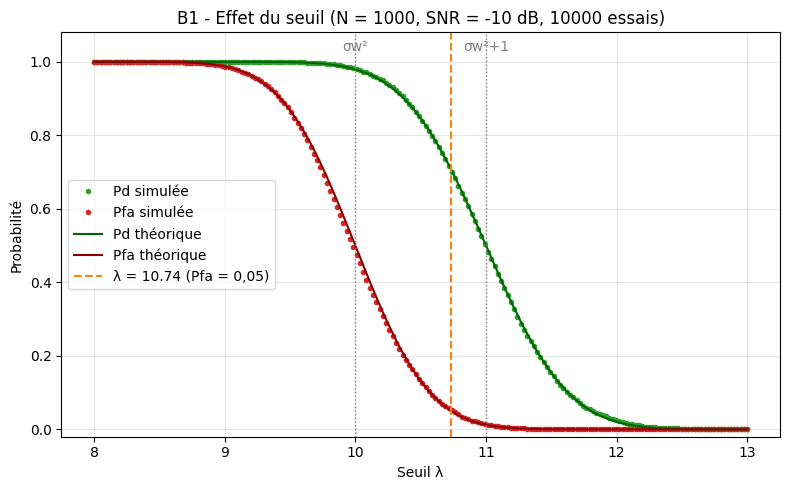

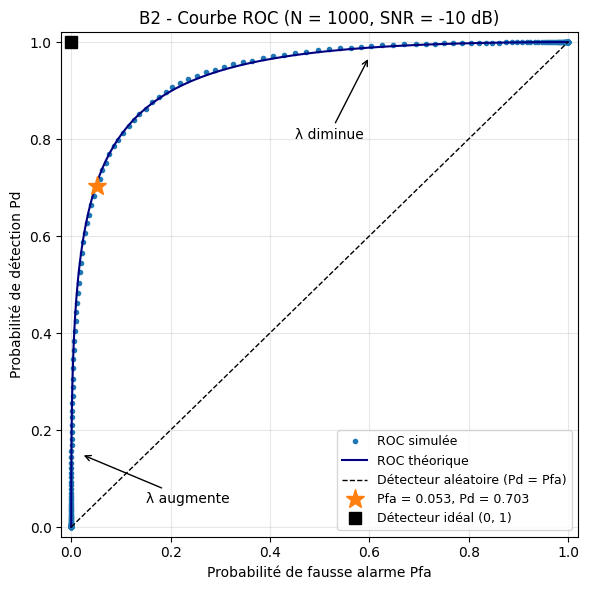

σw² = 10.0, 10000 essais par hypothèse

  lambda |    Pfa |     Pd
--------------------------
    9.00 |  0.987 |  1.000
    9.50 |  0.867 |  0.999
   10.00 |  0.482 |  0.981
   10.50 |  0.132 |  0.846
   10.74 |  0.053 |  0.703
   11.00 |  0.014 |  0.495
   11.50 |  0.001 |  0.152
   12.00 |  0.000 |  0.025


In [7]:
"""
TP Détection d'énergie en Smart Radio - Partie B : Pd et Pfa
B1 : effet du seuil -> tracer Pd(lambda) et Pfa(lambda)
B2 : courbe ROC     -> tracer Pd en fonction de Pfa
Paramètres : N = 1000, SNR = -10 dB, 10 000 essais Monte-Carlo
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(seed=0)

# ---------------- Paramètres ----------------
N = 1000
SNR_dB = -10
N_MC = 10000                      # nombre d'expériences indépendantes
Ps = 1.0
sigma_w2 = Ps / 10 ** (SNR_dB / 10)
sigma_w = np.sqrt(sigma_w2)


# ---------------- Simulation Monte-Carlo ----------------
def simuler_T(N, sigma_w, N_MC):
    """Retourne N_MC valeurs de T sous H0 et N_MC valeurs de T sous H1.
    Chaque ligne d'une matrice (N_MC x N) est une expérience indépendante."""
    # H0 : x = w
    w0 = sigma_w * rng.standard_normal((N_MC, N))
    T_H0 = np.mean(w0 ** 2, axis=1)
    # H1 : x = s + w
    s = 2 * rng.integers(0, 2, (N_MC, N)) - 1
    w1 = sigma_w * rng.standard_normal((N_MC, N))
    T_H1 = np.mean((s + w1) ** 2, axis=1)
    return T_H0, T_H1


T_H0, T_H1 = simuler_T(N, sigma_w, N_MC)

# ---------------- Balayage du seuil lambda ----------------
lambdas = np.linspace(8, 13, 200)       # plage large : de "tout détecter" à "rien détecter"
Pfa = np.array([np.sum(T_H0 > lam) / N_MC for lam in lambdas])   # Nfa / Ntests,H0
Pd = np.array([np.sum(T_H1 > lam) / N_MC for lam in lambdas])    # Nd  / Ntests,H1

# Courbes théoriques (approximation gaussienne, N grand)
std0 = np.sqrt(2 * sigma_w2 ** 2 / N)
std1 = np.sqrt((4 * sigma_w2 + 2 * sigma_w2 ** 2) / N)
Pfa_th = norm.sf((lambdas - sigma_w2) / std0)
Pd_th = norm.sf((lambdas - sigma_w2 - 1) / std1)

# Point de fonctionnement Pfa = 0,05
lam_05 = sigma_w2 + norm.isf(0.05) * std0
Pfa_05 = np.mean(T_H0 > lam_05)
Pd_05 = np.mean(T_H1 > lam_05)

# ---------------- B1 : Pd(lambda) et Pfa(lambda) ----------------
plt.figure(figsize=(8, 5))
plt.plot(lambdas, Pd, "o", ms=3, color="tab:green", label="Pd simulée")
plt.plot(lambdas, Pfa, "o", ms=3, color="tab:red", label="Pfa simulée")
plt.plot(lambdas, Pd_th, "-", color="darkgreen", lw=1.5, label="Pd théorique")
plt.plot(lambdas, Pfa_th, "-", color="darkred", lw=1.5, label="Pfa théorique")
plt.axvline(lam_05, color="tab:orange", ls="--", label=f"λ = {lam_05:.2f} (Pfa = 0,05)")
plt.axvline(sigma_w2, color="gray", ls=":", lw=1)
plt.axvline(sigma_w2 + 1, color="gray", ls=":", lw=1)
plt.text(sigma_w2, 1.03, "σw²", ha="center", color="gray")
plt.text(sigma_w2 + 1, 1.03, "σw²+1", ha="center", color="gray")
plt.xlabel("Seuil λ")
plt.ylabel("Probabilité")
plt.title(f"B1 - Effet du seuil (N = {N}, SNR = {SNR_dB} dB, {N_MC} essais)")
plt.ylim(-0.02, 1.08)
plt.grid(alpha=0.3)
plt.legend(loc="center left")
plt.tight_layout()
plt.savefig("B1_Pd_Pfa_seuil.png", dpi=150)

# ---------------- B2 : courbe ROC ----------------
plt.figure(figsize=(6, 6))
plt.plot(Pfa, Pd, "o", ms=3, color="tab:blue", label="ROC simulée")
plt.plot(Pfa_th, Pd_th, "-", color="navy", lw=1.5, label="ROC théorique")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Détecteur aléatoire (Pd = Pfa)")
plt.plot(Pfa_05, Pd_05, "*", ms=14, color="tab:orange",
         label=f"Pfa = {Pfa_05:.3f}, Pd = {Pd_05:.3f}")
plt.plot(0, 1, "s", ms=9, color="black", label="Détecteur idéal (0, 1)")
plt.annotate("λ diminue", xy=(0.6, 0.97), xytext=(0.45, 0.8),
             arrowprops=dict(arrowstyle="->"))
plt.annotate("λ augmente", xy=(0.02, 0.15), xytext=(0.15, 0.05),
             arrowprops=dict(arrowstyle="->"))
plt.xlabel("Probabilité de fausse alarme Pfa")
plt.ylabel("Probabilité de détection Pd")
plt.title(f"B2 - Courbe ROC (N = {N}, SNR = {SNR_dB} dB)")
plt.xlim(-0.02, 1.02)
plt.ylim(-0.02, 1.02)
plt.grid(alpha=0.3)
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("B2_ROC.png", dpi=150)

plt.show()

# ---------------- Résultats numériques ----------------
print(f"σw² = {sigma_w2:.1f}, {N_MC} essais par hypothèse\n")
print(f"{'lambda':>8} | {'Pfa':>6} | {'Pd':>6}")
print("-" * 26)
for lam in [9.0, 9.5, 10.0, 10.5, lam_05, 11.0, 11.5, 12.0]:
    print(f"{lam:>8.2f} | {np.mean(T_H0 > lam):>6.3f} | {np.mean(T_H1 > lam):>6.3f}")

N = 1000, 10000 essais, Pfa cible = 0.05

SNR (dB) |     σw² |        λ |    Pfa | Pd simulée | Pd théorique
------------------------------------------------------------------
     -15 |  31.623 |   33.992 |  0.049 |      0.173 |        0.182
     -12 |  15.849 |   17.064 |  0.044 |      0.390 |        0.413
     -10 |  10.000 |   10.755 |  0.049 |      0.690 |        0.705
      -8 |   6.310 |    6.777 |  0.053 |      0.952 |        0.951
      -5 |   3.162 |    3.400 |  0.051 |      1.000 |        1.000
       0 |   1.000 |    1.074 |  0.049 |      1.000 |        1.000
       5 |   0.316 |    0.340 |  0.048 |      1.000 |        1.000


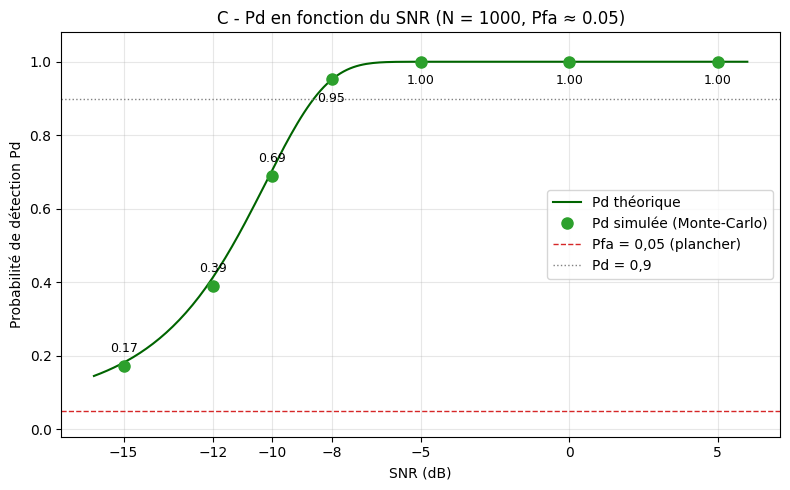

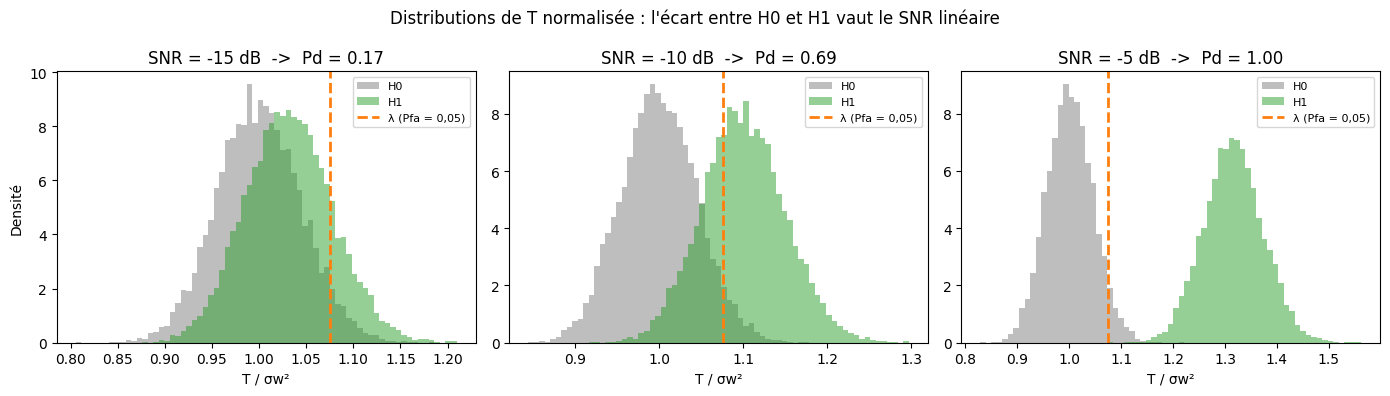

In [8]:
"""
TP Détection d'énergie en Smart Radio - Partie C : influence du SNR
N = 1000 fixé. Pour chaque SNR, on calibre le seuil lambda pour avoir Pfa ≈ 0,05,
puis on estime Pd par Monte-Carlo (10 000 essais).
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

rng = np.random.default_rng(seed=0)

# ---------------- Paramètres ----------------
N = 1000
N_MC = 10000
Ps = 1.0
Pfa_cible = 0.05
SNR_liste = [-15, -12, -10, -8, -5, 0, 5]     # en dB


def simuler_T_H0(N, sigma_w, n_essais):
    w = sigma_w * rng.standard_normal((n_essais, N))
    return np.mean(w ** 2, axis=1)


def simuler_T_H1(N, sigma_w, n_essais):
    s = 2 * rng.integers(0, 2, (n_essais, N)) - 1
    w = sigma_w * rng.standard_normal((n_essais, N))
    return np.mean((s + w) ** 2, axis=1)


# ---------------- Boucle sur les SNR ----------------
resultats = []
T_pour_figure = {}

for SNR_dB in SNR_liste:
    sigma_w2 = Ps / 10 ** (SNR_dB / 10)        # le bruit change avec le SNR
    sigma_w = np.sqrt(sigma_w2)

    # 1) Calibration du seuil : quantile à 95 % de T sous H0
    #    (seuil dépassé par 5 % des blocs de bruit seul -> Pfa = 0,05)
    T_cal = simuler_T_H0(N, sigma_w, N_MC)
    lam = np.quantile(T_cal, 1 - Pfa_cible)

    # 2) Nouvelles simulations indépendantes pour mesurer Pfa et Pd
    T_H0 = simuler_T_H0(N, sigma_w, N_MC)
    T_H1 = simuler_T_H1(N, sigma_w, N_MC)
    Pfa = np.mean(T_H0 > lam)
    Pd = np.mean(T_H1 > lam)

    # 3) Valeur théorique (approximation gaussienne)
    std0 = np.sqrt(2 * sigma_w2 ** 2 / N)
    std1 = np.sqrt((4 * sigma_w2 + 2 * sigma_w2 ** 2) / N)
    lam_th = sigma_w2 + norm.isf(Pfa_cible) * std0
    Pd_th = norm.sf((lam_th - sigma_w2 - Ps) / std1)

    resultats.append((SNR_dB, sigma_w2, lam, Pfa, Pd, Pd_th))
    T_pour_figure[SNR_dB] = (T_H0 / sigma_w2, T_H1 / sigma_w2, lam / sigma_w2)

# ---------------- Tableau ----------------
print(f"N = {N}, {N_MC} essais, Pfa cible = {Pfa_cible}\n")
print(f"{'SNR (dB)':>8} | {'σw²':>7} | {'λ':>8} | {'Pfa':>6} | {'Pd simulée':>10} | {'Pd théorique':>12}")
print("-" * 66)
for SNR_dB, s2, lam, Pfa, Pd, Pd_th in resultats:
    print(f"{SNR_dB:>8} | {s2:>7.3f} | {lam:>8.3f} | {Pfa:>6.3f} | {Pd:>10.3f} | {Pd_th:>12.3f}")

# ---------------- Figure 1 : Pd en fonction du SNR ----------------
SNR_fin = np.linspace(-16, 6, 200)
s2_fin = Ps / 10 ** (SNR_fin / 10)
std0_fin = np.sqrt(2 * s2_fin ** 2 / N)
std1_fin = np.sqrt((4 * s2_fin + 2 * s2_fin ** 2) / N)
lam_fin = s2_fin + norm.isf(Pfa_cible) * std0_fin
Pd_fin = norm.sf((lam_fin - s2_fin - Ps) / std1_fin)

plt.figure(figsize=(8, 5))
plt.plot(SNR_fin, Pd_fin, "-", color="darkgreen", lw=1.5, label="Pd théorique")
plt.plot([r[0] for r in resultats], [r[4] for r in resultats], "o", ms=8,
         color="tab:green", label="Pd simulée (Monte-Carlo)")
for SNR_dB, _, _, _, Pd, _ in resultats:
    plt.annotate(f"{Pd:.2f}", (SNR_dB, Pd), textcoords="offset points",
                 xytext=(0, -16 if Pd > 0.9 else 10), ha="center", fontsize=9)
plt.axhline(Pfa_cible, color="tab:red", ls="--", lw=1, label="Pfa = 0,05 (plancher)")
plt.axhline(0.9, color="gray", ls=":", lw=1, label="Pd = 0,9")
plt.xlabel("SNR (dB)")
plt.ylabel("Probabilité de détection Pd")
plt.title(f"C - Pd en fonction du SNR (N = {N}, Pfa ≈ {Pfa_cible})")
plt.xticks(SNR_liste)
plt.ylim(-0.02, 1.08)
plt.grid(alpha=0.3)
plt.legend(loc="center right")
plt.tight_layout()
plt.savefig("C_Pd_vs_SNR.png", dpi=150)

# ---------------- Figure 2 : pourquoi c'est difficile à faible SNR ----------------
# T est divisé par σw² pour comparer les SNR sur la même échelle :
# sous H0 la moyenne vaut 1, sous H1 elle vaut 1 + SNR.
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, SNR_dB in zip(ax, [-15, -10, -5]):
    t0, t1, l = T_pour_figure[SNR_dB]
    bins = np.linspace(min(t0.min(), t1.min()), max(t0.max(), t1.max()), 70)
    a.hist(t0, bins=bins, density=True, alpha=0.5, color="tab:gray", label="H0")
    a.hist(t1, bins=bins, density=True, alpha=0.5, color="tab:green", label="H1")
    a.axvline(l, color="tab:orange", ls="--", lw=2, label="λ (Pfa = 0,05)")
    Pd = np.mean(t1 > l)
    a.set_title(f"SNR = {SNR_dB} dB  ->  Pd = {Pd:.2f}")
    a.set_xlabel("T / σw²")
    a.legend(fontsize=8)
ax[0].set_ylabel("Densité")
fig.suptitle("Distributions de T normalisée : l'écart entre H0 et H1 vaut le SNR linéaire", fontsize=12)
plt.tight_layout()
plt.savefig("C_distributions_SNR.png", dpi=150)

plt.show()

SNR = -10 dB (σw² = 10), 10000 essais, Pfa cible = 0.05

     N |       λ |    Pfa | Pd simulée | Pd théorique | écart-type T|H0
----------------------------------------------------------------------
    10 |  18.298 |  0.050 |      0.081 |        0.082 |           4.428
    50 |  13.464 |  0.049 |      0.132 |        0.129 |           2.014
   100 |  12.427 |  0.053 |      0.176 |        0.175 |           1.420
   500 |  11.055 |  0.049 |      0.458 |        0.456 |           0.627
  1000 |  10.754 |  0.050 |      0.685 |        0.694 |           0.452
  5000 |  10.338 |  0.049 |      0.999 |        0.999 |           0.200


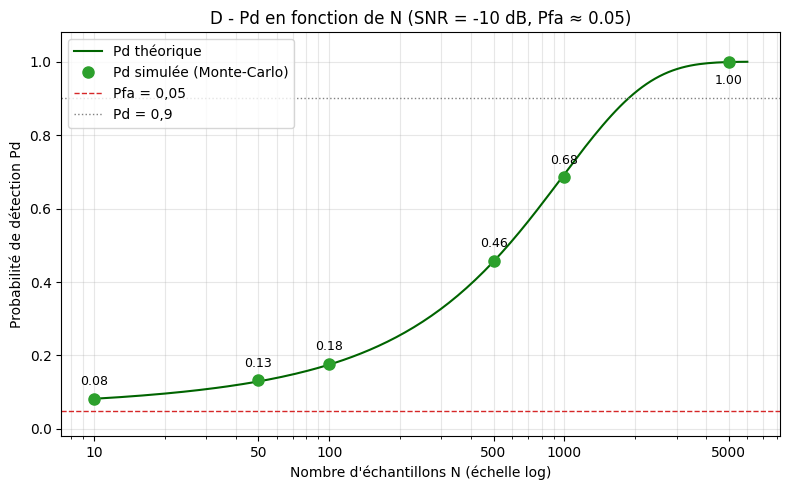

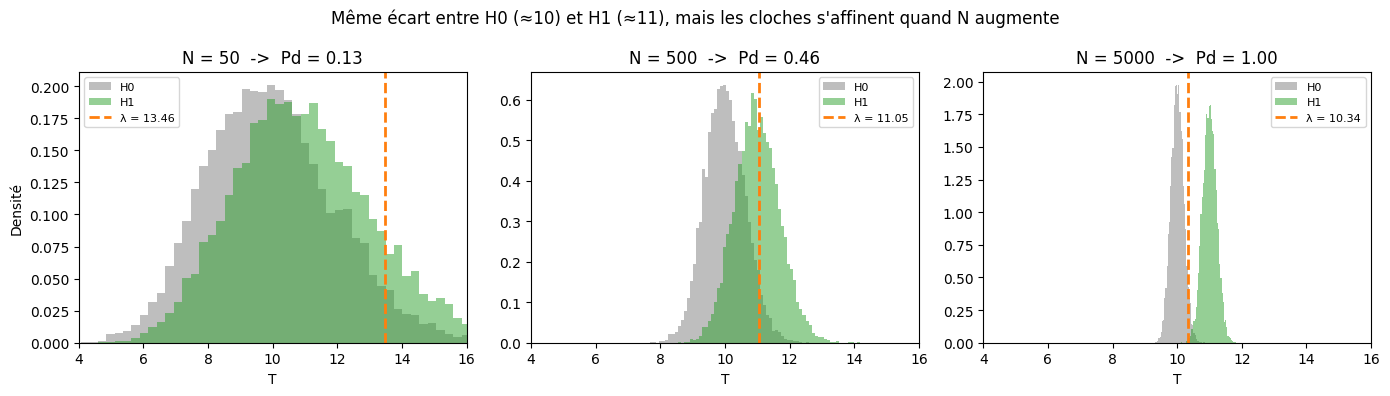

In [9]:
"""
TP Détection d'énergie en Smart Radio - Partie D : influence du nombre d'échantillons N
SNR = -10 dB fixé. Pour chaque N, on calibre lambda pour avoir Pfa ≈ 0,05,
puis on estime Pd par Monte-Carlo (10 000 essais).
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2, ncx2

rng = np.random.default_rng(seed=0)

# ---------------- Paramètres ----------------
SNR_dB = -10
N_MC = 10000
Ps = 1.0
Pfa_cible = 0.05
N_liste = [10, 50, 100, 500, 1000, 5000]
sigma_w2 = Ps / 10 ** (SNR_dB / 10)       # = 10
sigma_w = np.sqrt(sigma_w2)
TAILLE_LOT = 1000                          # simulation par lots pour limiter la mémoire


def simuler_T(N, n_essais, hypothese):
    """Retourne n_essais valeurs de T sous H0 ou H1 (calcul par lots)."""
    T = []
    for debut in range(0, n_essais, TAILLE_LOT):
        m = min(TAILLE_LOT, n_essais - debut)
        x = sigma_w * rng.standard_normal((m, N))           # bruit
        if hypothese == "H1":
            x = x + (2 * rng.integers(0, 2, (m, N)) - 1)    # + BPSK
        T.append(np.mean(x ** 2, axis=1))
    return np.concatenate(T)


def Pd_theorique(N):
    """Loi exacte : N*T/σw² suit un khi-deux à N degrés de liberté sous H0,
    et un khi-deux non central (paramètre N*Ps/σw²) sous H1."""
    lam = sigma_w2 * chi2.isf(Pfa_cible, N) / N
    return ncx2.sf(N * lam / sigma_w2, N, N * Ps / sigma_w2)


# ---------------- Boucle sur N ----------------
resultats = []
T_pour_figure = {}
for N in N_liste:
    lam = np.quantile(simuler_T(N, N_MC, "H0"), 1 - Pfa_cible)   # calibration
    T_H0 = simuler_T(N, N_MC, "H0")                               # mesure indépendante
    T_H1 = simuler_T(N, N_MC, "H1")
    Pfa = np.mean(T_H0 > lam)
    Pd = np.mean(T_H1 > lam)
    resultats.append((N, lam, Pfa, Pd, Pd_theorique(N), T_H0.std()))
    T_pour_figure[N] = (T_H0, T_H1, lam)

# ---------------- Tableau ----------------
print(f"SNR = {SNR_dB} dB (σw² = {sigma_w2:.0f}), {N_MC} essais, Pfa cible = {Pfa_cible}\n")
print(f"{'N':>6} | {'λ':>7} | {'Pfa':>6} | {'Pd simulée':>10} | {'Pd théorique':>12} | {'écart-type T|H0':>15}")
print("-" * 70)
for N, lam, Pfa, Pd, Pd_th, sd in resultats:
    print(f"{N:>6} | {lam:>7.3f} | {Pfa:>6.3f} | {Pd:>10.3f} | {Pd_th:>12.3f} | {sd:>15.3f}")

# ---------------- Figure 1 : Pd en fonction de N ----------------
N_fin = np.unique(np.logspace(1, np.log10(6000), 150).astype(int))
plt.figure(figsize=(8, 5))
plt.semilogx(N_fin, [Pd_theorique(n) for n in N_fin], "-", color="darkgreen", lw=1.5,
             label="Pd théorique")
plt.semilogx([r[0] for r in resultats], [r[3] for r in resultats], "o", ms=8,
             color="tab:green", label="Pd simulée (Monte-Carlo)")
for N, _, _, Pd, _, _ in resultats:
    plt.annotate(f"{Pd:.2f}", (N, Pd), textcoords="offset points",
                 xytext=(0, -16 if Pd > 0.9 else 10), ha="center", fontsize=9)
plt.axhline(Pfa_cible, color="tab:red", ls="--", lw=1, label="Pfa = 0,05")
plt.axhline(0.9, color="gray", ls=":", lw=1, label="Pd = 0,9")
plt.xticks(N_liste, [str(n) for n in N_liste])
plt.xlabel("Nombre d'échantillons N (échelle log)")
plt.ylabel("Probabilité de détection Pd")
plt.title(f"D - Pd en fonction de N (SNR = {SNR_dB} dB, Pfa ≈ {Pfa_cible})")
plt.ylim(-0.02, 1.08)
plt.grid(alpha=0.3, which="both")
plt.legend(loc="upper left")
plt.tight_layout()
plt.savefig("D_Pd_vs_N.png", dpi=150)

# ---------------- Figure 2 : pourquoi N améliore la détection ----------------
fig, ax = plt.subplots(1, 3, figsize=(14, 4), sharex=True)
for a, N in zip(ax, [50, 500, 5000]):
    t0, t1, lam = T_pour_figure[N]
    bins = np.linspace(min(t0.min(), t1.min()), max(t0.max(), t1.max()), 70)
    a.hist(t0, bins=bins, density=True, alpha=0.5, color="tab:gray", label="H0")
    a.hist(t1, bins=bins, density=True, alpha=0.5, color="tab:green", label="H1")
    a.axvline(lam, color="tab:orange", ls="--", lw=2, label=f"λ = {lam:.2f}")
    a.set_title(f"N = {N}  ->  Pd = {np.mean(t1 > lam):.2f}")
    a.set_xlabel("T")
    a.set_xlim(4, 16)
    a.legend(fontsize=8)
ax[0].set_ylabel("Densité")
fig.suptitle("Même écart entre H0 (≈10) et H1 (≈11), mais les cloches s'affinent quand N augmente",
             fontsize=12)
plt.tight_layout()
plt.savefig("D_distributions_N.png", dpi=150)

plt.show()